In [ ]:
import pandas as pd
import mysql.connector
import os

# List of CSV files and their corresponding table names
csv_files = [
    ('customers.csv', 'customers'),
    ('orders.csv', 'orders'),
    ('sellers.csv', 'sellers'),
    ('products.csv', 'products'),
    ('geolocation.csv', 'geolocation'),
    ('payments.csv', 'payments'),
    ('order_items.csv', 'order_items'),
    ('order_reviews', 'order_reviews'),
    
        # Added payments.csv for specific handling
]

# Connect to the MySQL database
conn = mysql.connector.connect(
    host='localhost',
    user='root',
    password='{Meena12$}',
    database='brazil_ecommerce'
)
cursor = conn.cursor()

# Folder containing the CSV files
folder_path = 'D:/Data Analyst Journey/Brazil Ecommerce Dataset'

def get_sql_type(dtype):
    if pd.api.types.is_integer_dtype(dtype):
        return 'INT'
    elif pd.api.types.is_float_dtype(dtype):
        return 'FLOAT'
    elif pd.api.types.is_bool_dtype(dtype):
        return 'BOOLEAN'
    elif pd.api.types.is_datetime64_any_dtype(dtype):
        return 'DATETIME'
    else:
        return 'TEXT'

for csv_file, table_name in csv_files:
    file_path = os.path.join(folder_path, csv_file)
    
    # Read the CSV file into a pandas DataFrame
    df = pd.read_csv(file_path)
    
    # Replace NaN with None to handle SQL NULL
    df = df.where(pd.notnull(df), None)
    
    # Debugging: Check for NaN values
    print(f"Processing {csv_file}")
    print(f"NaN values before replacement:\n{df.isnull().sum()}\n")

    # Clean column names
    df.columns = [col.replace(' ', '_').replace('-', '_').replace('.', '_') for col in df.columns]

    # Generate the CREATE TABLE statement with appropriate data types
    columns = ', '.join([f'`{col}` {get_sql_type(df[col].dtype)}' for col in df.columns])
    create_table_query = f'CREATE TABLE IF NOT EXISTS `{table_name}` ({columns})'
    cursor.execute(create_table_query)

    # Insert DataFrame data into the MySQL table
    for _, row in df.iterrows():
        # Convert row to tuple and handle NaN/None explicitly
        values = tuple(None if pd.isna(x) else x for x in row)
        sql = f"INSERT INTO `{table_name}` ({', '.join(['`' + col + '`' for col in df.columns])}) VALUES ({', '.join(['%s'] * len(row))})"
        cursor.execute(sql, values)

    # Commit the transaction for the current CSV file
    conn.commit()

# Close the connection
conn.close() 

Processing customers.csv
NaN values before replacement:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Processing orders.csv
NaN values before replacement:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Processing sellers.csv
NaN values before replacement:
seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

Processing products.csv
NaN values before replacement:
product_id                      0
product category              610
product_name_length           610
product_description_length    610
product_photos_qty            610
prod

In [13]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import mysql.connector

db = mysql.connector.connect(host ='localhost',
                             username = 'root',
                             password = '{Meena12$}',
                             database = 'brazil_ecommerce')

cur =db.cursor()

# Find the total sales per category. (use of multi JOIN)

In [77]:
query = """ select upper(products.product_category) AS category, round(sum(payments.payment_value),2) AS sales from products JOIN order_items on 
products.product_id= order_items.product_id 
JOIN payments on payments.order_id = order_items.order_id GROUP BY category """ 
cur.execute(query) 
data = cur.fetchall()
df = pd.DataFrame(data,columns = ['Category', 'Sales'])
df.head(10)

,Category,Sales
0,PERFUMERY,506738.66
1,FURNITURE DECORATION,1430176.39
2,TELEPHONY,486882.05
3,BED TABLE BATH,1712553.67
4,AUTOMOTIVE,852294.33
5,COMPUTER ACCESSORIES,1585330.45
6,HOUSEWARES,1094758.13
7,BABIES,539845.66
8,TOYS,619037.69
9,FURNITURE OFFICE,646826.49


# Calculate the percentage of orders that were paid in installments.

In [14]:
query = """ select (sum(case when payment_installments>=1 then 1 else 0 end))/count(*)*100 from payments""" 
cur.execute(query) 
data = cur.fetchall()
'the percentage of orders that were paid in installments', data[0][0]

('the percentage of orders that were paid in installments', Decimal('99.9981'))

# Count the number of customers from each state. 

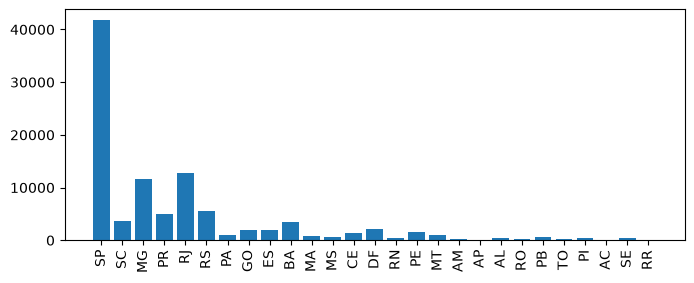

In [18]:
query = """select customer_state, count(customer_id) from customers GROUP BY customer_state""" 
cur.execute(query) 
data = cur.fetchall()
df = pd.DataFrame(data, columns = ['Customer_state', 'Number of Customer'])
plt.figure(figsize= (8,3))
plt.bar(df['Customer_state'],df['Number of Customer'])
plt.xticks(rotation=90)

plt.show()

# Calculate the number of orders per month in 2018.

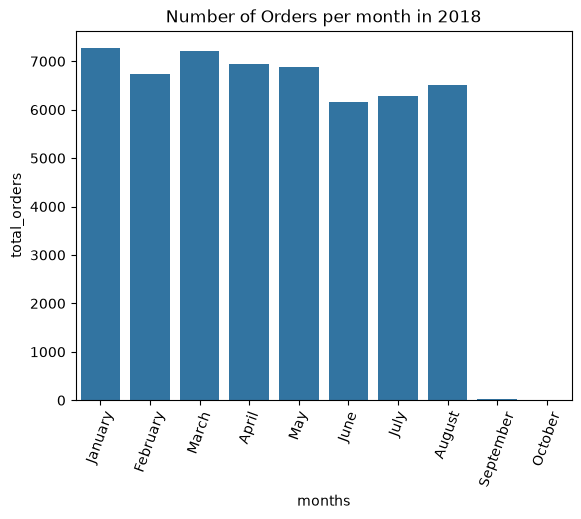

In [12]:
query = """select monthname(order_purchase_timestamp) AS months, count(order_id) AS total_orders from orders 
where year(order_purchase_timestamp) = 2018
GROUP BY months""" 
cur.execute(query) 
data = cur.fetchall()
df= pd.DataFrame(data, columns= ['months', 'total_orders'])
o = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October']
sns.barplot(x= df['months'], y= df['total_orders'], data = df, order = o)
plt.xticks(rotation = 70)
plt.title('Number of Orders per month in 2018')
plt.show()

# Find the average number of products per order, grouped by customer city.


In [19]:
query = """ with item_per_order as
(select orders.order_id, orders.customer_id ,count(order_items.order_item_id) AS ot from orders JOIN order_items on 
orders.order_id = order_items.order_id GROUP BY orders.order_id, orders.customer_id)

select customers.customer_city, round(avg(item_per_order.ot)) from customers JOIN item_per_order on 
customers.customer_id = item_per_order.customer_id GROUP BY customers.customer_city

""" 
cur.execute(query) 
data = cur.fetchall()
df = pd.DataFrame(data, columns = ['Customer City', 'Avg Product Per Order'])
df.head(10)

,Customer City,Avg Product Per Order
0,sao paulo,1
1,sao jose dos campos,1
2,porto alegre,1
3,indaial,1
4,treze tilias,1
5,rio de janeiro,1
6,mario campos,1
7,guariba,1
8,cuiaba,1
9,franca,1


# Calculate the percentage of total revenue contributed by each product category.


In [75]:
query = """ select products.product_category AS category, round((sum(payments.payment_value)/(select sum(payment_value) from payments))*100,2) as sales
from products JOIN order_items on 
products.product_id= order_items.product_id 
JOIN payments on payments.order_id = order_items.order_id GROUP BY category """ 
cur.execute(query) 
data = cur.fetchall()
data

[('perfumery', 3.17),
 ('Furniture Decoration', 8.93),
 ('telephony', 3.04),
 ('bed table bath', 10.7),
 ('automotive', 5.32),
 ('computer accessories', 9.9),
 ('housewares', 6.84),
 ('babies', 3.37),
 ('toys', 3.87),
 ('Furniture office', 4.04),
 ('Cool Stuff', 4.87),
 ('HEALTH BEAUTY', 10.35),
 ('pet Shop', 1.94),
 ('General Interest Books', 0.4),
 ('stationary store', 1.98),
 ('Watches present', 8.93),
 ('PCs', 1.74),
 ('climatization', 0.57),
 ('Construction Tools Construction', 1.51),
 ('sport leisure', 8.7),
 ('Bags Accessories', 1.17),
 ('electronics', 1.62),
 ('Casa Construcao', 0.85),
 ('Games consoles', 1.22),
 ('Fashion Bags and Accessories', 1.36),
 ('home appliances', 0.6),
 ('Garden tools', 5.24),
 ('Agro Industria e Comercio', 0.74),
 (None, 1.58),
 ('audio', 0.38),
 ('technical books', 0.16),
 ('Construction Tools Garden', 0.26),
 ('Market Place', 0.28),
 ('musical instruments', 1.46),
 ('Drink foods', 0.17),
 ('SIGNALIZATION AND SAFETY', 0.43),
 ('Furniture Kitchen Ser

# Identify the correlation between product price and the number of times a product has been purchase

In [8]:
query = """ select products.product_category, count(order_items.product_id), round(avg(order_items.price),2)
from products JOIN order_items on products.product_id = order_items.product_id 
GROUP BY products.product_category
""" 
cur.execute(query) 
data = cur.fetchall()
df = pd.DataFrame(data, columns = ['Product Category', 'Product_purchase_time', 'Price'])

arr1 = df['Product_purchase_time']
arr2 = df['Price']
a = np.corrcoef([arr1, arr2])
print('The correlation between product price and the number of times a product has been purchased is', a[0][-1])

The correlation between product price and the number of times a product has been purchased is -0.10631514167157562


# Calculate the total revenue generated by each seller, and rank them by revenue.


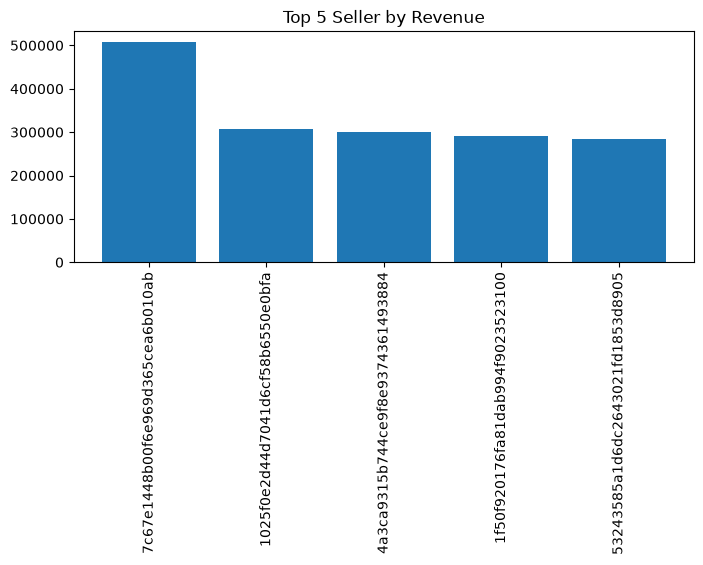

In [16]:
query = """ select * , dense_rank() over(ORDER BY Revenue desc) from 
(select order_items.seller_id AS Seller, round(sum(payments.payment_value),2) AS Revenue
from order_items JOIN payments on order_items.order_id = payments.order_id 
GROUP BY order_items.seller_id) AS a  """ 
cur.execute(query) 
data = cur.fetchall()
df = pd.DataFrame(data, columns = ['Seller', 'Revenue', 'Rank'])
df = df.head()
plt.figure(figsize=(8,3))
plt.bar(df['Seller'], df['Revenue'])
plt.xticks(rotation =90)
plt.title('Top 5 Seller by Revenue')
plt.show()

# Calculate the moving average of order values for each customer over their order history.


In [21]:
query = """select customer_id, order_purchase_timestamp, avg(payment_value) over(partition by customer_id ORDER BY order_purchase_timestamp
rows between 2 preceding and current row) AS mov_avg from  
(select orders.customer_id, orders.order_purchase_timestamp, payments.payment_value from
payments JOIN orders on payments.order_id = orders.order_id) as a""" 
cur.execute(query) 
data = cur.fetchall()
df = pd.DataFrame(data, columns=['Customer', 'Order Time', 'Mov_avg'])
df.head(10)

,Customer,Order Time,Mov_avg
0,00012a2ce6f8dcda20d059ce98491703,2017-11-14 16:08:26,114.739998
1,000161a058600d5901f007fab4c27140,2017-07-16 09:40:32,67.410004
2,0001fd6190edaaf884bcaf3d49edf079,2017-02-28 11:06:43,195.419998
3,0002414f95344307404f0ace7a26f1d5,2017-08-16 13:09:20,179.350006
4,000379cdec625522490c315e70c7a9fb,2018-04-02 13:42:17,107.010002
5,0004164d20a9e969af783496f3408652,2017-04-12 08:35:12,71.800003
6,000419c5494106c306a97b5635748086,2018-03-02 17:47:40,49.400002
7,00046a560d407e99b969756e0b10f282,2017-12-18 11:08:30,166.589996
8,00050bf6e01e69d5c0fd612f1bcfb69c,2017-09-17 16:04:44,85.230003
9,000598caf2ef4117407665ac33275130,2018-08-11 12:14:35,1255.709961


# Calculate the cumulative sales per month for each year.

In [70]:
query = """ select years, months, sum(payment) over(ORDER BY years, months) AS Cumulative_Sales from 
(select year(orders.order_purchase_timestamp) AS years, month(orders.order_purchase_timestamp) AS months, round(sum(payments.payment_value),2) 
AS payment from orders JOIN payments on orders.order_id = payments.order_id GROUP BY years, months ORDER BY years, months) AS a
""" 

cur.execute(query) 
data = cur.fetchall()
df = pd.DataFrame(data, columns=['Years', 'Months', 'Cumulative Sales'])
df.head(15)


,Years,Months,Cumulative Sales
0,2016,9,252.24
1,2016,10,59342.72
2,2016,12,59362.34
3,2017,1,197850.38
4,2017,2,489758.39
5,2017,3,939621.99
6,2017,4,1357410.02
7,2017,5,1950328.84
8,2017,6,2461605.22
9,2017,7,3053988.14


# Calculate the year-over-year growth rate of total sales.


In [48]:
query = """with a as (select year(orders.order_purchase_timestamp) AS years, round(sum(payments.payment_value),2) 
AS payment from orders JOIN payments on orders.order_id = payments.order_id GROUP BY years ORDER BY years)
select years, payment, lag(payment, 1)over (order by years), ((payment - lag(payment, 1)over (order by years))/ lag(payment, 1)over (order by years))*100 from a

""" 

cur.execute(query) 
data = cur.fetchall()
df = pd.DataFrame(data, columns= ['Year','payment', 'previous','year-over-year growth rate '])
df

,Year,payment,previous,year-over-year growth rate
0,2016,59362.34,NaN,NaN
1,2017,7249746.73,59362.34,12112.703761
2,2018,8699763.05,7249746.73,20.000924


# Identify the top 3 customers who spent the most money in each year.

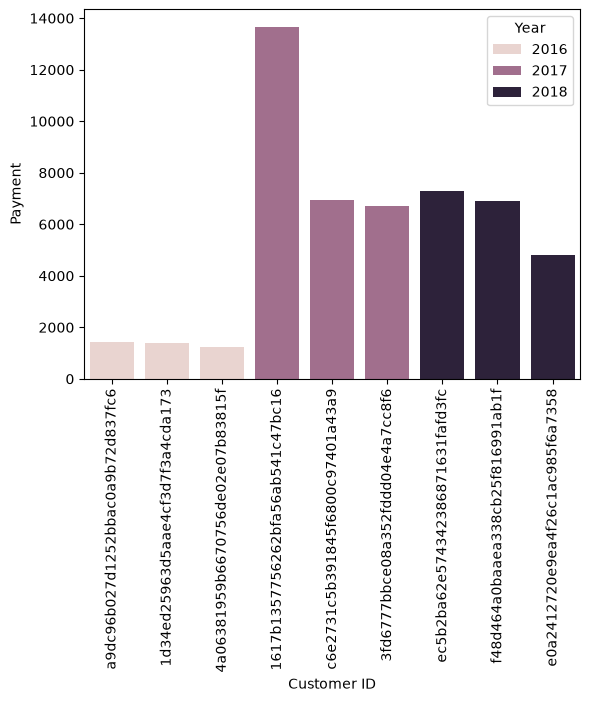

,Year,Customer ID,Payment,Rank
0,2016,a9dc96b027d1252bbac0a9b72d837fc6,1423.550049,1
1,2016,1d34ed25963d5aae4cf3d7f3a4cda173,1400.739990,2
2,2016,4a06381959b6670756de02e07b83815f,1227.780029,3
3,2017,1617b1357756262bfa56ab541c47bc16,13664.080078,1
4,2017,c6e2731c5b391845f6800c97401a43a9,6929.310059,2
5,2017,3fd6777bbce08a352fddd04e4a7cc8f6,6726.660156,3
6,2018,ec5b2ba62e574342386871631fafd3fc,7274.879883,1
7,2018,f48d464a0baaea338cb25f816991ab1f,6922.209961,2
8,2018,e0a2412720e9ea4f26c1ac985f6a7358,4809.439941,3


In [69]:
query= """select years, customer_id, payment, d_rank from
(select year(orders.order_purchase_timestamp) AS years, orders.customer_id, sum(payments.payment_value) AS payment,
dense_rank() over(partition by year(orders.order_purchase_timestamp) ORDER BY sum(payments.payment_value) desc) AS d_rank
from orders JOIN payments on payments.order_id = orders.order_id GROUP BY 
year(orders.order_purchase_timestamp), orders.customer_id) as a
where d_rank<=3;"""

cur.execute(query) 
data = cur.fetchall()
df = pd.DataFrame(data, columns= ['Year','Customer ID', 'Payment','Rank'])
sns.barplot(x='Customer ID', y='Payment', data = df, hue= 'Year')
plt.xticks(rotation =90)
plt.show()
df


# List all unique cities where customers are located.

In [3]:
query = """ select distinct customer_city from customers""" 
cur.execute(query) 
data = cur.fetchall()
data

[('franca',),
 ('sao bernardo do campo',),
 ('sao paulo',),
 ('mogi das cruzes',),
 ('campinas',),
 ('jaragua do sul',),
 ('timoteo',),
 ('curitiba',),
 ('belo horizonte',),
 ('montes claros',),
 ('rio de janeiro',),
 ('lencois paulista',),
 ('caxias do sul',),
 ('piracicaba',),
 ('guarulhos',),
 ('pacaja',),
 ('florianopolis',),
 ('aparecida de goiania',),
 ('santo andre',),
 ('goiania',),
 ('cachoeiro de itapemirim',),
 ('sao jose dos campos',),
 ('sao roque',),
 ('camacari',),
 ('resende',),
 ('sumare',),
 ('novo hamburgo',),
 ('sao luis',),
 ('sao jose',),
 ('santa barbara',),
 ('ribeirao preto',),
 ('ituiutaba',),
 ('taquarituba',),
 ('sao jose dos pinhais',),
 ('barrinha',),
 ('parati',),
 ('dourados',),
 ('trindade',),
 ('cascavel',),
 ('fortaleza',),
 ('brasilia',),
 ('pelotas',),
 ('porto alegre',),
 ('salto',),
 ('jundiai',),
 ('cacapava',),
 ('sao vicente',),
 ('uberlandia',),
 ('botelhos',),
 ('sao goncalo',),
 ('araucaria',),
 ('nova iguacu',),
 ('areia branca',),
 ('campo

# Count the number of orders placed in 2017.

In [4]:
query = """ select count(order_id) from orders where year(order_purchase_timestamp)=2017""" 
cur.execute(query) 
data = cur.fetchall()
'total order placed in 2017', data[0][0]

('total order placed in 2017', 90202)